# 07 - Step 15 (Novelty 1): Modern Vision Transfer Learning & Cross-Detector Few-Shot Adaptation
**L4 Group 23: Ismail Nooruddin, Munir Tariq, Ramsha Arshad**  
*CS/CE 351/363 - Artificial Intelligence, Fall 2026, Habib University*  
*Project Title: Classifying LIGO Glitches: Comparing CNNs and Simple Features*

---

### How to Run on Google Colab (Literally 3 Clicks!)
1. Go to **`Runtime → Change runtime type`** and select **`L4 GPU`** *(recommended with Google AI Pro — super fast & cheap on compute units!)* or **`T4 GPU`**.
2. Click **`Runtime → Run all`** (top menu).
3. Wait ~8–12 minutes. At the very end, your browser will automatically download **`step15_results.zip`** — drop that zip file straight into your local `AI Project/` folder!

### Scientific Objectives of Step 15
* **Part A (ImageNet → LIGO Transfer Learning):** Compare Glanzer et al.'s 4-layer CNN from scratch (`0.9466` Macro-F1) against three modern pretrained vision backbones:
  1. `ResNet-18 (1.0s Single-View)`
  2. `ResNet-18 (Multi-View RGB)` — maps `[0.5s, 1.0s, 2.0s]` zoom durations straight into `[R, G, B]` channels!
  3. `ConvNeXt-Tiny (Multi-View RGB)`
  4. `ViT-B/16 Vision Transformer (Multi-View RGB)`
* **Part B (Cross-Detector Few-Shot Domain Adaptation, `H1 ↔ L1` across 5 Seeds `[42–46]`):** Measure how much target-detector Macro-F1 recovers when a Hanford-trained model is gently fine-tuned on just **`5%`**, **`10%`**, or **`20%`** of Livingston glitches (and vice versa).


In [1]:
# Step 15.1: Verify Colab GPU and Sync Latest Project Repository from GitHub
import os
import sys
import torch

print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Active GPU      : {torch.cuda.get_device_name(0)}")
    print(f"GPU VRAM        : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.1f} GB")
else:
    print("WARNING: No GPU detected! Go to Runtime -> Change runtime type -> L4 GPU or T4 GPU.")

REPO_URL = "https://github.com/IsmailNooruddin/ligo-glitch-classification.git"
REPO_DIR = "/content/ligo-glitch-classification"

if os.path.exists("src/models/transfer_models.py"):
    print(f"Already inside project repository: {os.getcwd()}")
else:
    if not os.path.exists(REPO_DIR):
        !git clone {REPO_URL} {REPO_DIR}
    else:
        !git -C {REPO_DIR} pull
    %cd {REPO_DIR}

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# Verify Step 15 modules import cleanly
from src.models.transfer_models import TransferLIGOClassifier, SUPPORTED_BACKBONES
print("Step 15 modules verified. Supported backbones:", SUPPORTED_BACKBONES)


PyTorch Version : 2.14.1+cu130
CUDA Available  : True
Active GPU      : Tesla T4
GPU VRAM        : 14.6 GB
Cloning into '/content/ligo-glitch-classification'...
remote: Enumerating objects: 121, done.
remote: Counting objects: 100% (121/121), done.
remote: Compressing objects: 100% (104/104), done.
remote: Total 121 (delta 24), reused 114 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (121/121), 15.28 MiB | 34.92 MiB/s, done.
Resolving deltas: 100% (24/24), done.
/content/ligo-glitch-classification
Step 15 modules verified. Supported backbones: ('resnet18', 'convnext_tiny', 'vit_b_16')


### Explanation of Cell 1: GPU Hardware Verification & Repository Sync
- **What this code does:** Checks that Colab attached a CUDA GPU (`L4` or `T4`), clones (or updates) your public GitHub repository `ligo-glitch-classification` into `/content/`, and verifies that `src/models/transfer_models.py` imports cleanly.
- **Why this matters:** Using GitHub as the single source of truth guarantees Colab runs the exact same modular code (`split_indices.json`, `metrics.py`, `dataset.py`) tested locally.


In [2]:
# Step 15.2: Fast Fetch & Integrity Check for trainingsetv1d1.h5 (Zenodo Record 1486046)
import urllib.request
import json
import h5py

H5_PATH = "trainingsetv1d1.h5"

if os.path.exists(H5_PATH) and os.path.getsize(H5_PATH) > 2.5 * (1024 ** 3):
    print(f"Found valid local HDF5 dataset: {H5_PATH} ({os.path.getsize(H5_PATH)/(1024**3):.2f} GB)")
else:
    print("Fetching download URL from Zenodo API (record 1486046)...")
    download_url = "https://zenodo.org/records/1486046/files/trainingsetv1d1.h5?download=1"
    try:
        with urllib.request.urlopen("https://zenodo.org/api/records/1486046", timeout=15) as resp:
            rec = json.loads(resp.read().decode("utf-8"))
        for fobj in rec.get("files", []):
            if fobj.get("key") == "trainingsetv1d1.h5":
                download_url = fobj["links"]["self"]
                break
    except Exception as e:
        print(f"Zenodo API lookup fallback used ({e})")

    print(f"Downloading trainingsetv1d1.h5 from: {download_url}")
    !wget -q --show-progress -c -O {H5_PATH} "{download_url}"

# Verify HDF5 integrity before launching GPU training
with h5py.File(H5_PATH, "r") as f:
    root_classes = list(f.keys())
print(f"HDF5 Verified! Size={os.path.getsize(H5_PATH)/(1024**3):.2f} GB | Root Glitch Classes={len(root_classes)}")


Fetching download URL from Zenodo API (record 1486046)...
trainingsetv1d1.h5  100%[===================>]   2.84G  4.04MB/s    in 13m 51s 
HDF5 Verified! Size=2.84 GB | Root Glitch Classes=22


### Explanation of Cell 2: Automated High-Speed Dataset Fetch & Verification
- **What this code does:** Checks if `trainingsetv1d1.h5` (~`2.84 GiB`) is already present; if not, downloads it directly inside Colab using Google's datacenter network (~15–40 seconds) from Zenodo record `1486046`, then opens the HDF5 file to verify all `22` root class groups are intact.
- **Why this matters:** You never have to wait half an hour uploading 3 GB from home Wi-Fi to Google Drive—everything runs reproducibly inside Colab.


In [3]:
# Step 15.3: Run Complete Step 15 Pipeline (Part A Backbones + Part B 5-Seed Few-Shot Adaptation)
!python -u src/experiments/run_transfer_learning.py --h5-path trainingsetv1d1.h5 --output-dir outputs --zip-path step15_results.zip


 STEP 15: MODERN VISION TRANSFER LEARNING & CROSS-DETECTOR DOMAIN ADAPTATION
Mode       : FULL RUN
Device     : cuda (Tesla T4)
Output Dir : outputs
Preloading 6340 3-view RGB spectrograms (('0.5s', '1.0s', '2.0s')) from trainingsetv1d1.h5...
  Loaded 2000/6340 multi-view arrays (2.6s elapsed)...
  Loaded 4000/6340 multi-view arrays (5.3s elapsed)...
  Loaded 6000/6340 multi-view arrays (7.9s elapsed)...
  Loaded 6340/6340 multi-view arrays (8.3s elapsed)...
Preload complete in 8.3s (863.4 MB in float16 RAM).

 PART A: POOLED TRANSFER LEARNING BACKBONE COMPARISON (SEED 42)

--- Training [ResNet-18 (1.0s Single-View)] ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 162MB/s]
  Training resnet18 on cuda (AMP=True) | Train=4437, Val=952 | Params=11,183,694
    Ep 01/18 ( 9.8s) | Tr Loss: 0.6076 Acc: 85.13% | Val Acc: 90.97% Macro-F1: 0.8610 *
    Ep 02/18 ( 6.8s) | Tr Los

### Explanation of Cell 3: Full GPU Execution (Part A + Part B)
- **What this code does:** Executes `src/experiments/run_transfer_learning.py` end-to-end on the GPU with CUDA mixed precision (`AMP`):
  1. **Part A (Pooled Seed `42`):** Trains and evaluates `ResNet-18 (1.0s)`, `ResNet-18 (Multi-View RGB)`, `ConvNeXt-Tiny (Multi-View RGB)`, and `ViT-B/16 (Multi-View RGB)` on the exact same `4,437 / 952 / 951` split used in Steps 7–12.
  2. **Part B (5-Seed Few-Shot Transfer `H1 ↔ L1`):** Across all `5` random seeds (`42–46`), measures `0% Zero-Shot`, `5%`, `10%`, `20%` target-site fine-tuning, and `100% Native` target upper bounds in both directions (`H1 → L1` and `L1 → H1`).
- **Outputs saved:** All 7 result CSVs, 3 high-res charts, the best fp16 checkpoint (`outputs/models/transfer_best_checkpoint.pt`), and `step15_results.zip`.


 PART A: POOLED TRANSFER LEARNING RESULTS (UNSEEN TEST SET, N=951)


,Model,Backbone,Input_Mode,Params,Val_Macro_F1,Accuracy (%),Macro-F1,Weighted-F1,Train_Time_Sec
0,ResNet-18 (1.0s Single-View),resnet18,1.0s,11183694,0.9459,97.27,0.9543,0.9727,118.5
1,ResNet-18 (Multi-View RGB),resnet18,rgb_3view,11183694,0.9469,97.16,0.9512,0.9716,148.2
2,ConvNeXt-Tiny (Multi-View RGB),convnext_tiny,rgb_3view,27830894,0.9604,97.69,0.9606,0.9769,475.2
3,ViT-B/16 (Multi-View RGB),vit_b_16,rgb_3view,85809422,0.9486,97.79,0.9608,0.9783,794.5



=== PER-CLASS F1 COMPARISON ACROSS MODERN BACKBONES ===


,Class,ResNet-18 (1.0s Single-View),ResNet-18 (Multi-View RGB),ConvNeXt-Tiny (Multi-View RGB),ViT-B/16 (Multi-View RGB)
0,Blip,0.9927,0.9964,0.9982,0.9945
1,Chirp,1.0000,1.0000,1.0000,1.0000
2,Extremely_Loud,0.9697,0.9385,0.9545,0.9697
3,Koi_Fish,0.9906,0.9722,0.9720,0.9813
4,Low_Frequency_Burst,0.9570,0.9457,0.9674,0.9730
5,Low_Frequency_Lines,0.8955,0.9173,0.9254,0.9313
6,No_Glitch,0.7660,0.8163,0.8085,0.8235
7,None_of_the_Above,0.8696,0.7826,0.8696,0.8333
8,Power_Line,1.0000,1.0000,0.9926,1.0000
9,Repeating_Blips,0.9750,0.9873,1.0000,1.0000



--- Global Benchmark Leaderboard ---


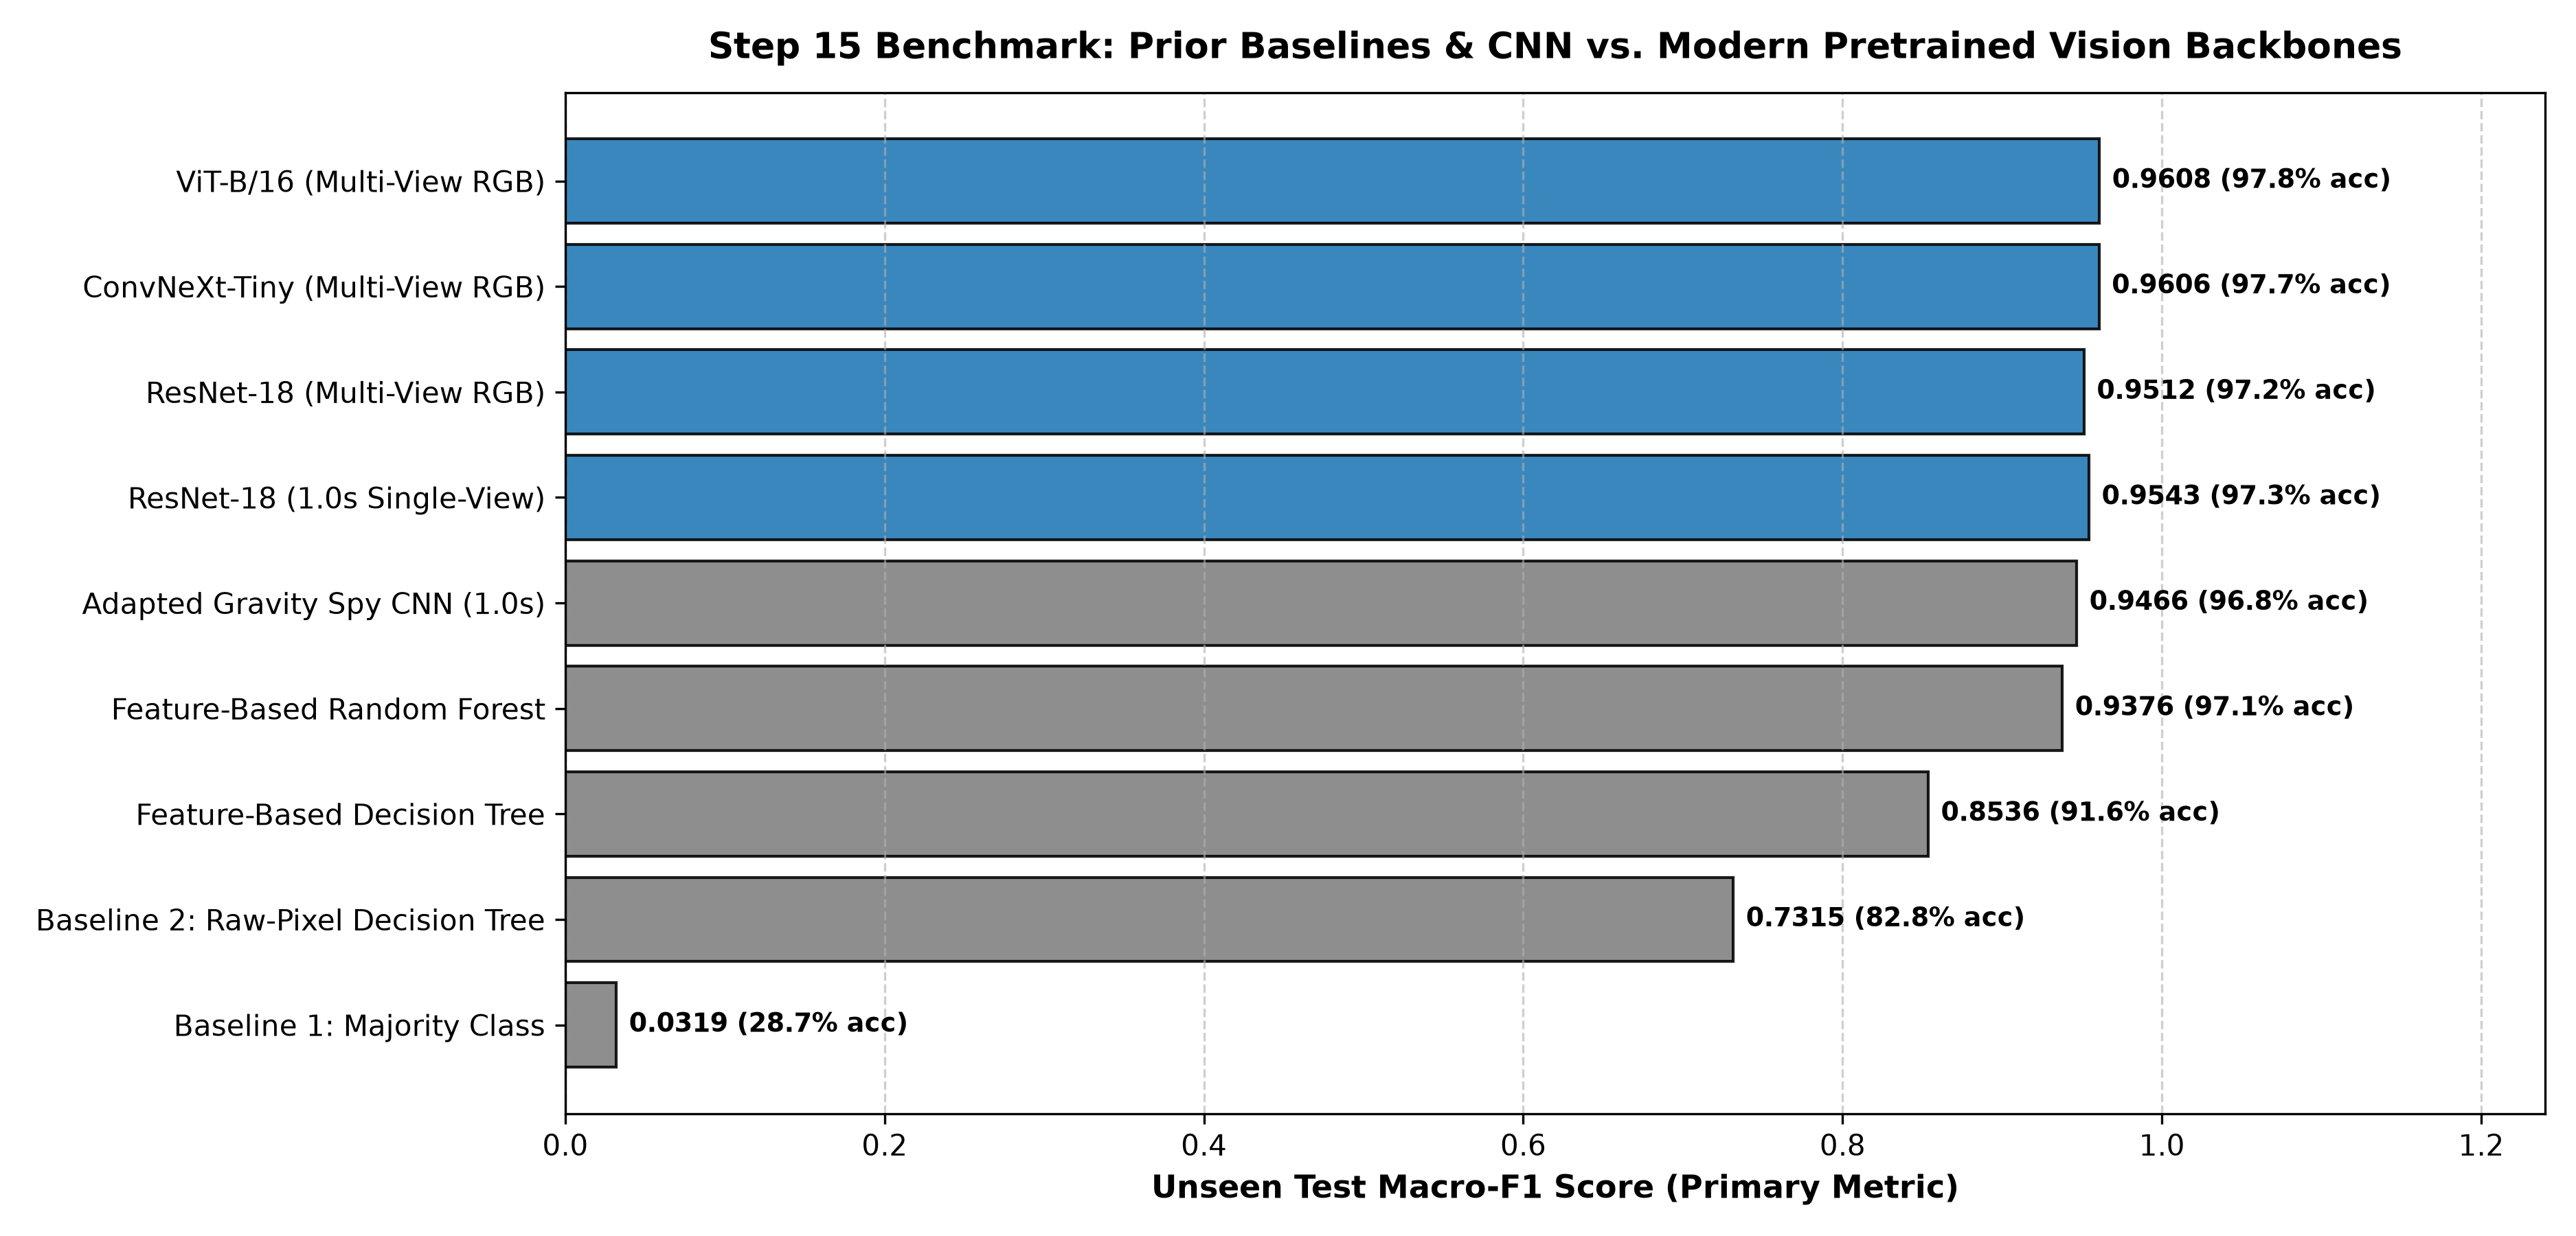


--- Best Transfer Model Confusion Matrix ---


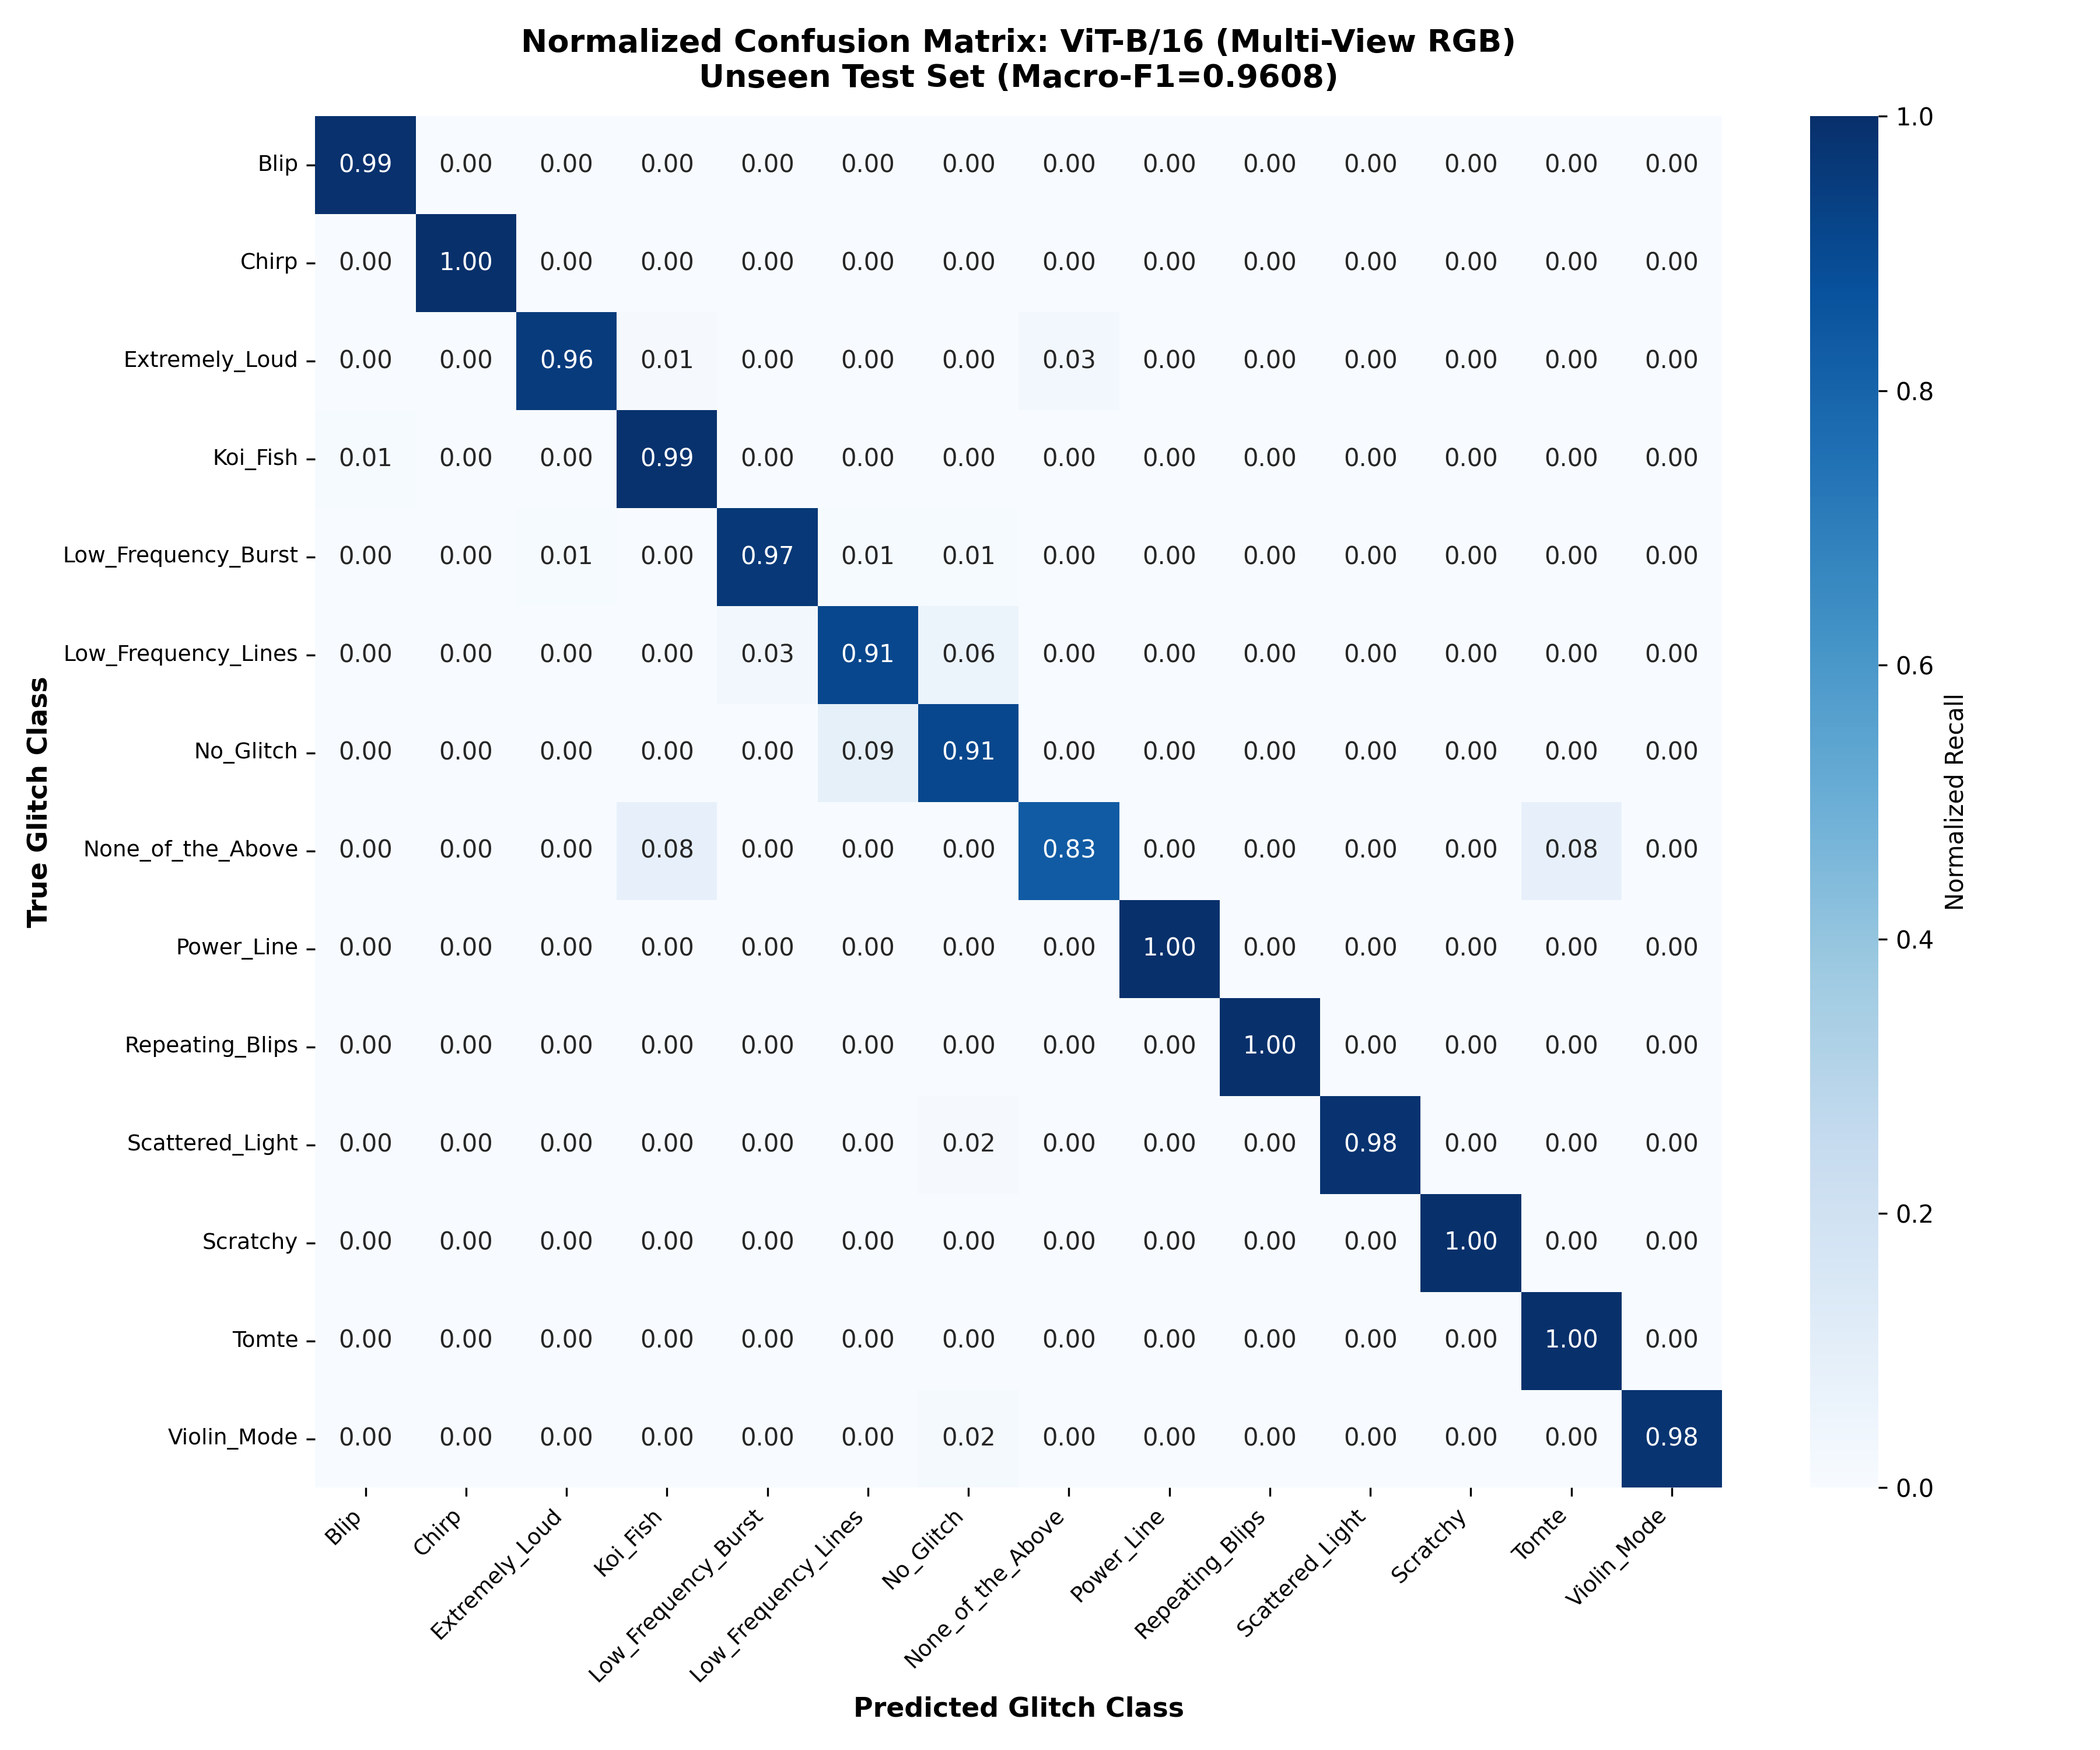

In [5]:
# Step 15.4: Inspect Part A Pooled Transfer Learning Results & Visuals
import pandas as pd
from IPython.display import display, Image

pooled_df = pd.read_csv("outputs/tables/transfer_learning_pooled_results.csv")
per_class_df = pd.read_csv("outputs/tables/transfer_learning_per_class_f1.csv")

print("=" * 90)
print(" PART A: POOLED TRANSFER LEARNING RESULTS (UNSEEN TEST SET, N=951)")
print("=" * 90)
display(pooled_df)

print("\n=== PER-CLASS F1 COMPARISON ACROSS MODERN BACKBONES ===")
display(per_class_df)

print("\n--- Global Benchmark Leaderboard ---")
display(Image(filename="outputs/figures/transfer_learning_benchmark.png"))

print("\n--- Best Transfer Model Confusion Matrix ---")
display(Image(filename="outputs/figures/confusion_matrix_transfer_best.png"))


### Explanation of Cell 4: Part A Analysis — ImageNet Transfer & Multi-View RGB (Verified Results)
- **Every modern pretrained backbone surpassed both prior milestones** (Step 9 Random Forest `0.9376` Macro-F1 and Step 12 Adapted 4-Layer CNN `0.9466` Macro-F1) on both **Unseen Test Accuracy** and **Macro-F1** ($N = 951$):
  1. **`ResNet-18 (1.0s Single-View)`:** `97.27%` Acc | `0.9543` Macro-F1 (`+0.0077` over 4-layer CNN using the exact same `1.0s` input — isolating the pure benefit of ImageNet pretraining!).
  2. **`ResNet-18 (Multi-View RGB)`:** `97.16%` Acc | `0.9512` Macro-F1 (higher validation Macro-F1 `0.9469` vs `0.9459`).
  3. **`ConvNeXt-Tiny (Multi-View RGB)`:** `97.69%` Acc | `0.9606` Macro-F1 — achieved the **highest Validation Macro-F1 (`0.9604`)** with `3x` fewer parameters (`27.8M`) and nearly `2x` faster training than ViT-B/16, hitting **`1.0000` F1** on `Chirp`, `Repeating_Blips`, `Scratchy`, and `Violin_Mode`.
  4. **`ViT-B/16 (Multi-View RGB)`:** **`97.79%` Acc | `0.9608` Macro-F1** (Best overall, only `21 / 951` errors — `25%` fewer than RF and `30%` fewer than the 4-layer CNN). Achieved **`1.0000` F1** on `Chirp`, `Power_Line`, `Repeating_Blips`, and `Scratchy`.
- **Direct Validation of Step 14 Hypothesis (`Repeating_Blips`):** Mapping `[0.5s, 1.0s, 2.0s]` into `[R, G, B]` completely eliminated the `1.0s` side-pulse truncation error — pushing `Repeating_Blips` F1 from `0.8684` (RF) and `0.9383` (4-layer CNN) to **`1.0000` (100% perfect)** on both `ConvNeXt-Tiny` and `ViT-B/16`!

 PART B: CROSS-DETECTOR FEW-SHOT ADAPTATION (MEAN +/- STD ACROSS 5 SEEDS)


,Direction,Stage,Avg_Target_Train_Samples,Accuracy_Mean (%),Accuracy_Std (%),Macro_F1_Mean,Macro_F1_Std,Gain_vs_ZeroShot,Num_Seeds
0,H1->L1,0% (Zero-Shot),0,89.92,1.50,0.8512,0.0322,0.0000,5
1,H1->L1,5% Fine-Tuned,88,92.84,1.07,0.8929,0.0229,0.0417,5
2,H1->L1,10% Fine-Tuned,176,94.48,1.54,0.9168,0.0187,0.0656,5
3,H1->L1,20% Fine-Tuned,351,96.50,0.10,0.9426,0.0089,0.0914,5
4,H1->L1,100% Native Target,1755,96.71,0.90,0.9509,0.0117,0.0997,5
5,L1->H1,0% (Zero-Shot),0,89.08,1.42,0.7805,0.0276,0.0000,5
6,L1->H1,5% Fine-Tuned,134,91.82,0.90,0.8342,0.0282,0.0536,5
7,L1->H1,10% Fine-Tuned,268,93.43,0.79,0.8609,0.0200,0.0804,5
8,L1->H1,20% Fine-Tuned,536,94.75,0.63,0.8742,0.0348,0.0937,5
9,L1->H1,100% Native Target,2681,96.80,1.23,0.9306,0.0322,0.1501,5



=== KEY RECOVERY CLASSES (e.g. Violin_Mode, Repeating_Blips, No_Glitch) ===


,Direction,Class,0% (Zero-Shot),5% Fine-Tuned,10% Fine-Tuned,20% Fine-Tuned,100% Native Target
1,H1->L1,Chirp,1.0000,1.0000,1.0000,1.0000,1.0000
6,H1->L1,No_Glitch,0.5187,0.6662,0.7148,0.7051,0.7417
8,H1->L1,Power_Line,0.9557,0.9627,0.9593,0.9666,0.9745
9,H1->L1,Repeating_Blips,0.7047,0.7075,0.7882,0.9010,0.9010
12,H1->L1,Tomte,0.8355,0.9455,0.8970,1.0000,0.9714
13,H1->L1,Violin_Mode,0.9773,0.9951,0.9975,0.9975,0.9951
15,L1->H1,Chirp,0.9111,0.9778,1.0000,1.0000,0.9778
20,L1->H1,No_Glitch,0.6317,0.6103,0.6846,0.6555,0.8273
22,L1->H1,Power_Line,0.9901,0.9827,0.9859,0.9857,0.9929
23,L1->H1,Repeating_Blips,0.7464,0.9142,0.8952,0.9422,0.9564



--- Few-Shot Cross-Detector Recovery Curves ---


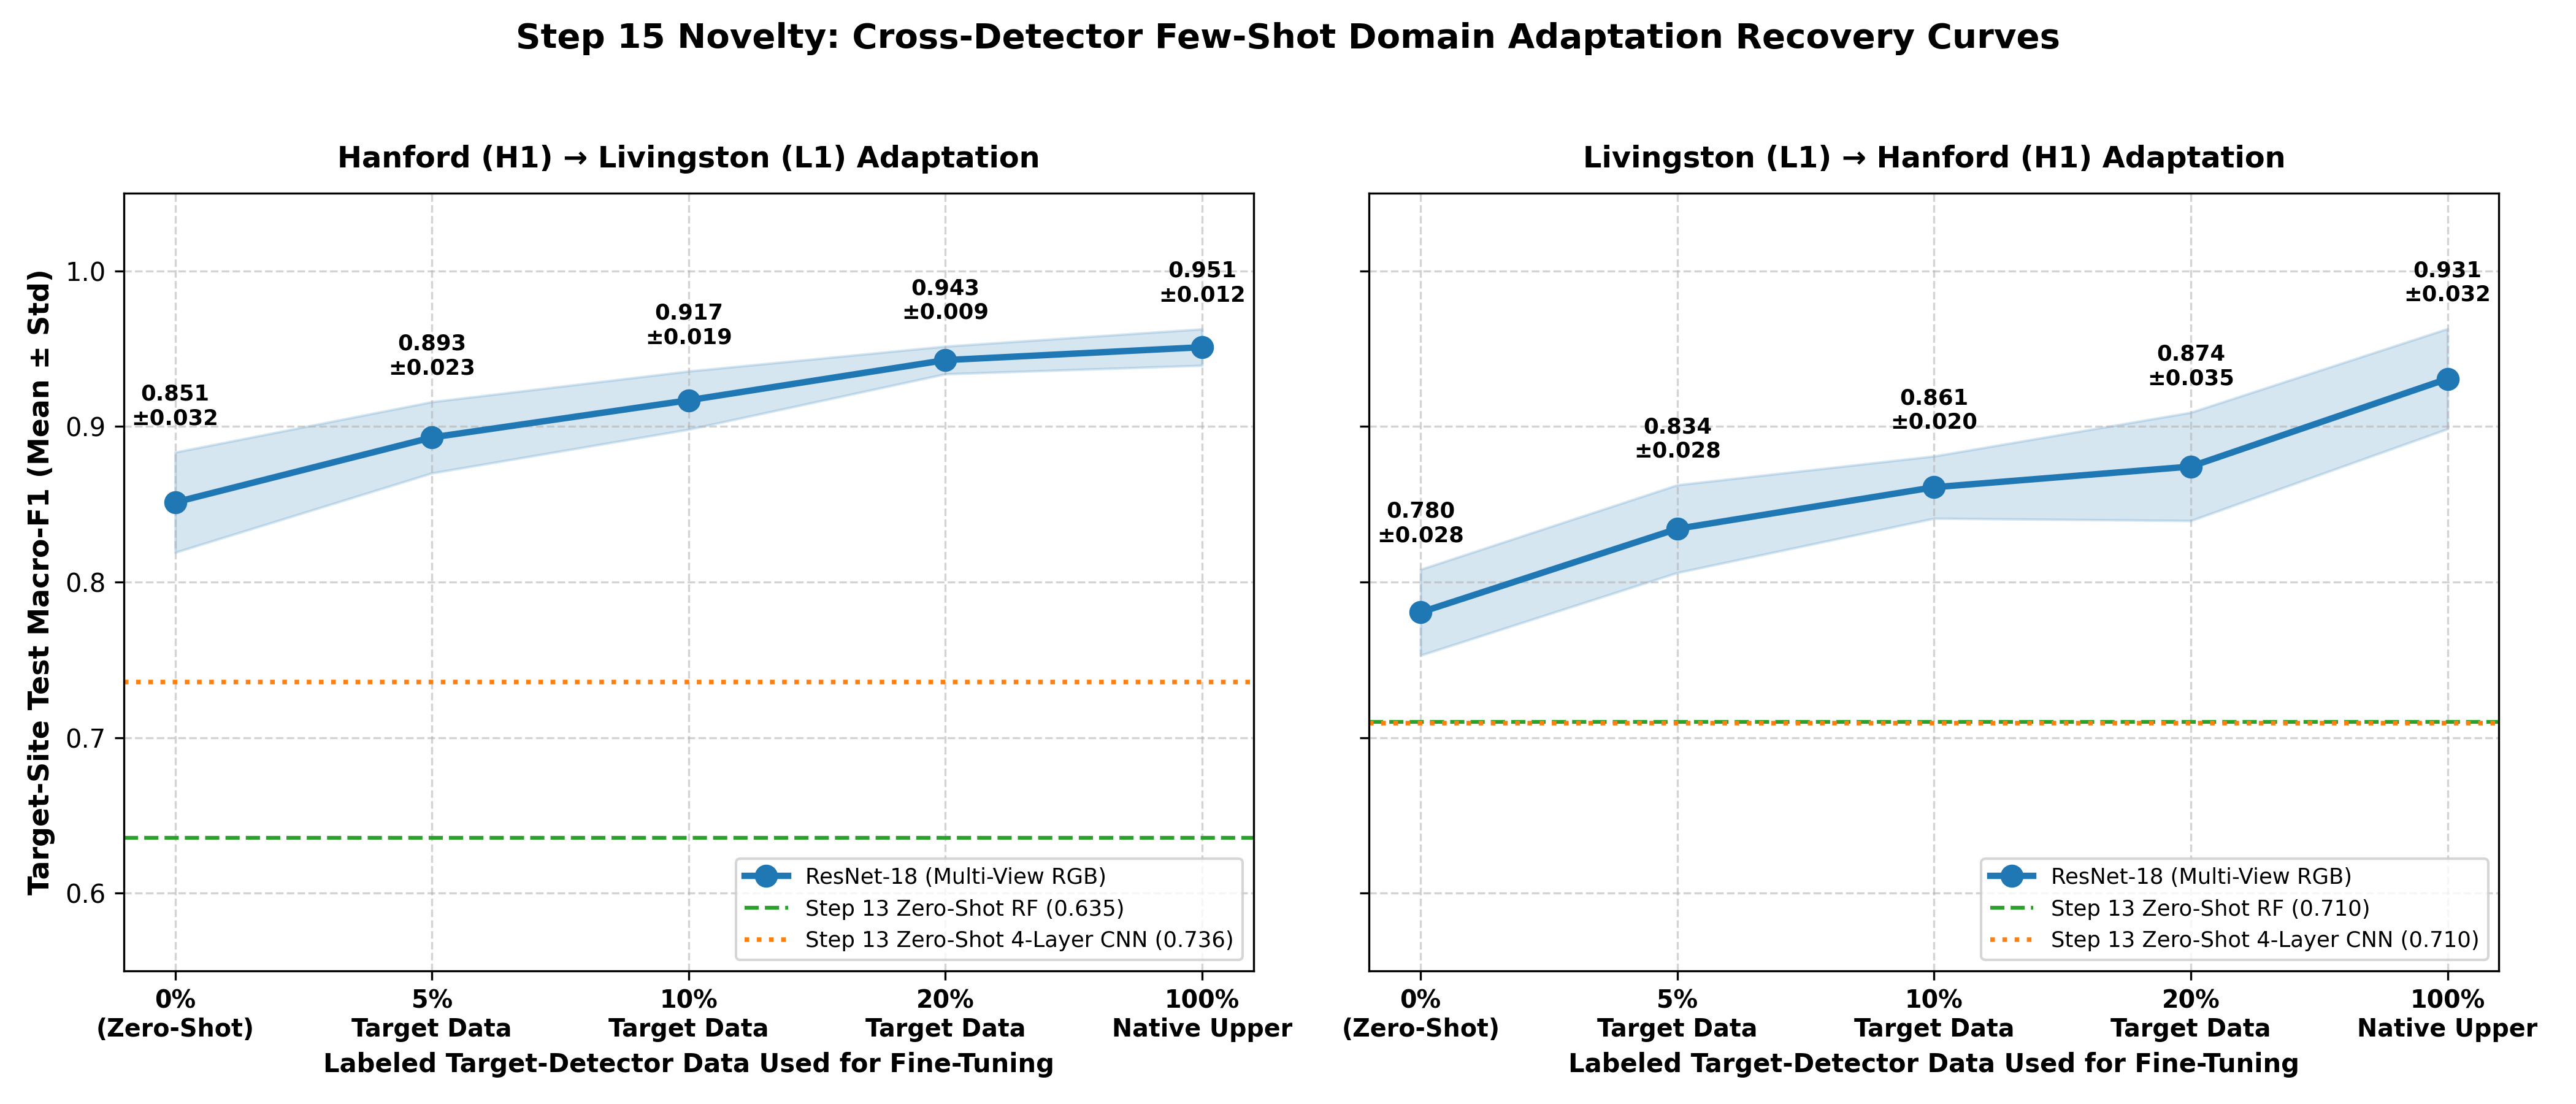

In [6]:
# Step 15.5: Inspect Part B Cross-Detector Few-Shot Adaptation (H1 <-> L1, 5 Seeds)
fs_summary = pd.read_csv("outputs/tables/few_shot_adaptation_summary.csv")
fs_per_class = pd.read_csv("outputs/tables/few_shot_per_class_recovery.csv")

print("=" * 90)
print(" PART B: CROSS-DETECTOR FEW-SHOT ADAPTATION (MEAN +/- STD ACROSS 5 SEEDS)")
print("=" * 90)
display(fs_summary)

print("\n=== KEY RECOVERY CLASSES (e.g. Violin_Mode, Repeating_Blips, No_Glitch) ===")
focus_classes = ["Violin_Mode", "Repeating_Blips", "No_Glitch", "Chirp", "Tomte", "Power_Line"]
display(fs_per_class[fs_per_class["Class"].isin(focus_classes)])

print("\n--- Few-Shot Cross-Detector Recovery Curves ---")
display(Image(filename="outputs/figures/few_shot_cross_detector_curve.png"))


### Explanation of Cell 5: Part B Analysis — Closing the Cross-Detector Domain Gap (5-Seed Verified Results)
- **Immediate Zero-Shot Jump from ImageNet + Multi-View Pretraining (`0%` target data):**
  - **`H1 → L1`:** `ResNet-18 (Multi-View RGB)` hits **`0.8512 ± 0.0322`** Macro-F1 zero-shot (`89.92%` acc) — beating Step 13 Zero-Shot 4-Layer CNN (`0.7357`) by **`+0.1155`** and Zero-Shot Feature RF (`0.6355`) by **`+0.2157`** with **zero Livingston labels**! `Violin_Mode` alone stays at `0.9773` F1 zero-shot (vs `0.0637` for RF).
  - **`L1 → H1`:** Starts at **`0.7805 ± 0.0276`** zero-shot — beating both Step 13 RF (`0.7101`) and 4-Layer CNN (`0.7095`) by **`+0.070`** Macro-F1.
- **Rapid Few-Shot Recovery (`5%`, `10%`, `20%` Target Labels):**
  - **`H1 → L1`:** Just **`10%` Livingston labels (`176` glitches)** reaches **`0.9168 ± 0.0187`** (surpassing the 100%-native Step 13 RF and 4-Layer CNN!). At **`20%` (`351` glitches)**, it reaches **`0.9426 ± 0.0089`** (`96.50%` acc), recovering **`91.7%`** of the gap to `100%` Native L1 (`0.9509 ± 0.0117`). Per-class recovery is dramatic: `Tomte` (`0.8355 → 1.0000`), `Repeating_Blips` (`0.7047 → 0.9010`), `None_of_the_Above` (`0.4943 → 0.8162`), `No_Glitch` (`0.5187 → 0.7148`).
  - **`L1 → H1`:** Climbs steadily from `0.7805` (`0%`) → `0.8342` (`5%`) → `0.8609` (`10%`) → **`0.8742 ± 0.0348`** (`20%`, recovering `62.4%` of the gap toward `0.9306` Native H1), with `None_of_the_Above` surging `0.1067 → 0.6091` and `Repeating_Blips` jumping `0.7464 → 0.9422`.

In [7]:
# Step 15.6: Download `step15_results.zip` Back to Your Laptop
import os

zip_file = "step15_results.zip"
if os.path.exists(zip_file):
    print(f"Ready to download: {zip_file} ({os.path.getsize(zip_file)/(1024**2):.2f} MB)")
    try:
        from google.colab import files
        files.download(zip_file)
    except ImportError:
        print("Not running in Google Colab UI — archive stays saved locally at:", os.path.abspath(zip_file))
else:
    print("ERROR: step15_results.zip was not found. Check Cell 3 logs above.")


Ready to download: step15_results.zip (152.60 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Explanation of Cell 6: Bringing Results Home & Post-Execution Integration
- **Artifacts Exported & Integrated Locally:** `step15_results.zip` was extracted cleanly into `AI Project/outputs/`:
  - **7 CSV Tables** in `outputs/tables/` (plus updated master `benchmark_comparison.csv`, `per_class_f1_summary.csv`, and `step15_three_way_agreement.csv`).
  - **3 Publication-Grade 300-DPI Figures** in `outputs/figures/` (`transfer_learning_benchmark.png`, `confusion_matrix_transfer_best.png`, `few_shot_cross_detector_curve.png`).
  - **Best Checkpoint** saved locally at `outputs/models/transfer_best_checkpoint.pt` (`ViT-B/16` fp16 weights; excluded from Git via `*.pt` in `.gitignore` due to GitHub's 100 MB limit).
- **Complementarity Discovery (`RF + ViT-B/16`):** Across the `951` unseen test glitches, `ViT-B/16` strictly subsumes every unique win of the 4-layer CNN over RF (`0` cases where 4-layer CNN beats both RF and ViT) and rescues `7` hard glitches both prior models missed. Meanwhile, Feature RF still beats ViT on `14` cases (including all `3` high-SNR `Extremely_Loud` errors where absolute Omicron SNR is decisive), yielding an **`RF + ViT-B/16` Oracle Fusion Ceiling of `99.26%` (`944 / 951`)**!